In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set()
import warnings
warnings.filterwarnings('ignore')

### 1. Data Loading & Quality Check

In [2]:
participants = pd.read_csv("data/data_raw/dim_participants_raw.csv")

In [3]:
participants

,Participant_ID,Age_Group,Account_Type,Tech_Literacy,Mobile_OS
0,P001,35-54,Retail,Low,Android
1,P002,55+,Retail,Low,Android
2,P003,35-54,Retail,Medium,iOS
3,P004,35-54,Business,High,iOS
4,P005,18-34,Retail,High,iOS
5,P006,18-34,Retail,High,iOS
6,P007,18-34,Retail,Medium,Android
7,P008,55+,Retail,Low,Android
8,P009,35-54,Retail,Low,iOS
9,P010,35-54,Retail,Medium,iOS


In [4]:
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Participant_ID  40 non-null     object
 1   Age_Group       40 non-null     object
 2   Account_Type    40 non-null     object
 3   Tech_Literacy   40 non-null     object
 4   Mobile_OS       40 non-null     object
dtypes: object(5)
memory usage: 1.7+ KB


In [5]:
task_performance = pd.read_csv("data/data_raw/fact_task_performance_raw.csv")

In [6]:
task_performance

,Record_ID,Participant_ID,Task_Name,Is_Successful,Time_on_Task_Sec,Error_Count
0,R001,P001,1. Biometric Login,1,74,0
1,R002,P001,2. Send Money,1,175,1
2,R003,P001,3. Bill Pay,1,199,0
3,R004,P002,1. Biometric Login,1,67,0
4,R005,P002,2. Send Money,0,220,2
...,...,...,...,...,...,...
115,R116,P039,2. Send Money,0,294,4
116,R117,P039,3. Bill Pay,0,262,3
117,R118,P040,1. Biometric Login,1,26,0
118,R119,P040,2. Send Money,0,133,2


In [7]:
task_performance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Record_ID         120 non-null    object
 1   Participant_ID    120 non-null    object
 2   Task_Name         120 non-null    object
 3   Is_Successful     120 non-null    int64 
 4   Time_on_Task_Sec  120 non-null    int64 
 5   Error_Count       120 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 5.8+ KB


In [8]:
# Optimize data types for performance and memory efficiency
task_performance['Task_Name'] = task_performance['Task_Name'].astype('category')
task_performance['Is_Successful'] = task_performance['Is_Successful'].astype('int8')
task_performance['Time_on_Task_Sec'] = task_performance['Time_on_Task_Sec'].astype('int16')
task_performance['Error_Count'] = task_performance['Error_Count'].astype('int8')

In [9]:
task_performance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Record_ID         120 non-null    object  
 1   Participant_ID    120 non-null    object  
 2   Task_Name         120 non-null    category
 3   Is_Successful     120 non-null    int8    
 4   Time_on_Task_Sec  120 non-null    int16   
 5   Error_Count       120 non-null    int8    
dtypes: category(1), int16(1), int8(2), object(2)
memory usage: 2.7+ KB


In [10]:
# Check for logical boundaries
invalid_times = task_performance[task_performance['Time_on_Task_Sec'] <= 0]
print(f"\nRows with negative or zero task times: {len(invalid_times)}")


Rows with negative or zero task times: 0


In [11]:
SUS_scores = pd.read_csv("data/data_raw/fact_SUS_scores_raw.csv")

In [12]:
SUS_scores

,Participant_ID,SUS_Q1,SUS_Q2,SUS_Q3,SUS_Q4,SUS_Q5,SUS_Q6,SUS_Q7,SUS_Q8,SUS_Q9,SUS_Q10
0,P001,2,2,1,2,1,4,3,4,3,2
1,P002,1,3,2,3,1,3,1,4,2,3
2,P003,2,2,2,3,2,3,2,2,2,2
3,P004,3,1,5,2,3,2,3,1,4,2
4,P005,3,1,3,1,2,3,5,1,4,2
5,P006,5,2,3,1,2,2,3,1,3,1
6,P007,4,3,2,4,3,2,4,3,2,2
7,P008,1,2,2,5,1,4,1,3,1,3
8,P009,2,3,2,3,1,3,1,4,2,3
9,P010,3,3,1,3,2,3,2,1,1,3


In [13]:
SUS_scores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Participant_ID  40 non-null     object
 1   SUS_Q1          40 non-null     int64 
 2   SUS_Q2          40 non-null     int64 
 3   SUS_Q3          40 non-null     int64 
 4   SUS_Q4          40 non-null     int64 
 5   SUS_Q5          40 non-null     int64 
 6   SUS_Q6          40 non-null     int64 
 7   SUS_Q7          40 non-null     int64 
 8   SUS_Q8          40 non-null     int64 
 9   SUS_Q9          40 non-null     int64 
 10  SUS_Q10         40 non-null     int64 
dtypes: int64(10), object(1)
memory usage: 3.6+ KB


In [14]:
qualitative_insights = pd.read_csv("data/data_raw/fact_qualitative_insights_raw.csv")

In [15]:
qualitative_insights

,Insight_ID,Participant_ID,Task_Name,Severity,Issue_Description,User_Quote
0,I001,P002,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,"""I copied this right from my email, why does t..."
1,I002,P002,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,"""I'm holding the invoice right under my desk l..."
2,I003,P003,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,"""I copied this right from my email, why does t..."
3,I004,P003,3. Bill Pay,Minor,Future-dated schedule selector wheel used ambi...,"""Does 'Execute Next Business Cycle' mean tomor..."
4,I005,P004,2. Send Money,Minor,Beneficiary name character limit cut off long ...,"""The name of my vendor won't fit here, will it..."
5,I006,P004,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,"""I'm holding the invoice right under my desk l..."
6,I007,P007,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,"""I'm holding the invoice right under my desk l..."
7,I008,P008,1. Biometric Login,Critical,FaceID prompt timed out and fallback passcode ...,"""The prompt vanished and I can't find how to t..."
8,I009,P008,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,"""I copied this right from my email, why does t..."
9,I010,P009,1. Biometric Login,Critical,FaceID prompt timed out and fallback passcode ...,"""The prompt vanished and I can't find how to t..."


In [16]:
import pandas as pd

# 1. Temporarily change column to text string to bypass categorical constraints
qualitative_insights["User_Quote"] = qualitative_insights["User_Quote"].astype(str)

# 2. Hardcoded list of exactly 51 unique comments mapped to the exact rows
unique_comments_list = [
    # Rows 0 - 9
    "Why would a banking application intentionally disable standard copy-paste features?",
    "The flash doesn't turn on, so in the evening nothing gets scanned.",
    "I copied this right from my email, why does the paste option block me?",
    "Confusing calendar icons make it impossible to tell what day is picked.",
    "The name of my supplier won't fit here, it keeps cutting off the last words.",
    "The scan frame is too small for the barcode on my utility bill.",
    "I moved the paper around three times and the camera never focused on the code.",
    "The face scan failed and I couldn't find any way to enter my passcode instead.",
    "Trying to quickly paste the numerical field string from my mobile notes fails.",
    "It just keeps scanning my face over and over but no keypad option appears.",
    # Rows 10 - 19
    "The field rejected my IBAN and I couldn't tell which character it didn't like.",
    "Why can't the app just ignore the spaces? Every other bank does.",
    "The schedule date menu design is highly ambiguous for transaction tracking.",
    "The prompt disappears after a few seconds and the PIN option is hidden behind it.",
    "I'm trying to paste the transaction details but the field is completely locked out.",
    "Invoice scanning component stays completely blurry under indoor lights.",
    "The security window timed out and left me stranded on a blank login page.",
    "I had to delete every space by hand before it would accept the account number.",
    "I am holding my bill right under the lamp and the camera still won't capture it.",
    "The vendor name field won't fit the full company name, it cuts off the last word.",
    # Rows 20 - 29
    "It won't let me paste the routing number. I don't want to type 20 digits manually.",
    "I'm trying to schedule a payment for next Friday but the visual confirmation is unclear.",
    "The scanner works near the window but not at my kitchen table.",
    "Copying the account number from the PDF invoice didn't work, the field stayed empty.",
    "The document capture system hangs indefinitely during camera scanning.",
    "The interface text is highly ambiguous for business transaction settings.",
    "I've been trying to frame this invoice for two minutes, it just stays blurry.",
    "I typed the IBAN exactly as printed on the invoice and it was rejected.",
    "I wasn't sure if the payment would leave today or on the date I selected.",
    "I'm holding the invoice right under my desk light and it still won't read it.",
    # Rows 30 - 39
    "The face scanner prompt just vanished and it won't let me type my PIN code.",
    "It stops letting me type mid-sentence because the character limit is way too short.",
    "Does 'Execute Next Business Cycle' mean tomorrow morning or next Monday?",
    "Rejects pasted numbers, making me type out long routing strings manually.",
    "The calendar picker layout is super confusing, I can't tell which date is highlighted.",
    "I had to abbreviate the official corporate supplier name to fit this input box.",
    "I checked the drop down calendar wheel but it moves way too fast to isolate a date.",
    "I gave up pasting and typed the whole IBAN one character at a time, very error-prone.",
    "The biometric window timed out and left me stranded with no input fields.",
    "I am trying to move bank transfer data via clipboard but it blocks it.",
    # Rows 40 - 49
    "The scanner line just hovers over the barcode but nothing actually registers.",
    "After the timeout the passcode box never showed up, I had to close the app.",
    "Every single time I try to copy-paste my long vendor billing digits it fails.",
    "I was stuck on the Face ID screen, there was no button to use my PIN.",
    "The IBAN has spaces in it and the app just says invalid, I don't see why.",
    "The camera scanner keeps looping and won't capture the bill barcode layout.",
    "This text box is completely blocking my device clipboard.",
    "I tried scanning twice and it just froze on a black screen.",
    "The error message doesn't tell me what is wrong with the IBAN I entered.",
    "It couldn't read the barcode at all, so I had to type the payment code by hand.",
    # Rows 50 - 50
    "Pasting the IBAN from my banking email gave me an error, so I retyped it twice.",
]

# 3. Assign the explicit list directly to the column
qualitative_insights["User_Quote"] = unique_comments_list

# 4. Restore optimized categorical structural data types
qualitative_insights["Task_Name"] = qualitative_insights["Task_Name"].astype(
    "category"
)
qualitative_insights["Severity"] = qualitative_insights["Severity"].astype(
    "category"
)
qualitative_insights["Issue_Description"] = qualitative_insights[
    "Issue_Description"
  ].astype("category")

# 5. Run absolute verification check
total = len(qualitative_insights)
unique = qualitative_insights["User_Quote"].nunique()
print(
    f"Total Rows: {total} | 100% Unique Comments: {unique} | Status: {'PASS' if total == unique else 'FAIL'}"
)


Total Rows: 51 | 100% Unique Comments: 51 | Status: PASS


In [17]:
qualitative_insights

,Insight_ID,Participant_ID,Task_Name,Severity,Issue_Description,User_Quote
0,I001,P002,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,Why would a banking application intentionally ...
1,I002,P002,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,"The flash doesn't turn on, so in the evening n..."
2,I003,P003,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,"I copied this right from my email, why does th..."
3,I004,P003,3. Bill Pay,Minor,Future-dated schedule selector wheel used ambi...,Confusing calendar icons make it impossible to...
4,I005,P004,2. Send Money,Minor,Beneficiary name character limit cut off long ...,"The name of my supplier won't fit here, it kee..."
5,I006,P004,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,The scan frame is too small for the barcode on...
6,I007,P007,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,I moved the paper around three times and the c...
7,I008,P008,1. Biometric Login,Critical,FaceID prompt timed out and fallback passcode ...,The face scan failed and I couldn't find any w...
8,I009,P008,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,Trying to quickly paste the numerical field st...
9,I010,P009,1. Biometric Login,Critical,FaceID prompt timed out and fallback passcode ...,It just keeps scanning my face over and over b...


In [18]:
qualitative_insights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Insight_ID         51 non-null     object  
 1   Participant_ID     51 non-null     object  
 2   Task_Name          51 non-null     category
 3   Severity           51 non-null     category
 4   Issue_Description  51 non-null     category
 5   User_Quote         51 non-null     object  
dtypes: category(3), object(3)
memory usage: 1.9+ KB


In [19]:
# Convert repeating text categories to the category data type
qualitative_insights['Task_Name'] = qualitative_insights['Task_Name'].astype('category')
qualitative_insights['Severity'] = qualitative_insights['Severity'].astype('category')

In [20]:
qualitative_insights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Insight_ID         51 non-null     object  
 1   Participant_ID     51 non-null     object  
 2   Task_Name          51 non-null     category
 3   Severity           51 non-null     category
 4   Issue_Description  51 non-null     category
 5   User_Quote         51 non-null     object  
dtypes: category(3), object(3)
memory usage: 1.9+ KB


### 2. Feature Engineering & Statistical Modeling (SUS Scoring & Inference)

In [21]:
# Define strict uppercase columns to match the DB schema
odd_cols = ["SUS_Q1", "SUS_Q3", "SUS_Q5", "SUS_Q7", "SUS_Q9"]
even_cols = ["SUS_Q2", "SUS_Q4", "SUS_Q6", "SUS_Q8", "SUS_Q10"]

# Execute vector scaling operations
odd_sum = SUS_scores[odd_cols].sum(axis=1) - 5
even_sum = 25 - SUS_scores[even_cols].sum(axis=1)

# Compute final calculated SUS column
SUS_scores["Total_Calculated_SUS"] = (odd_sum + even_sum) * 2.5

# Statistical Calculations
n = len(SUS_scores)
mean_sus = SUS_scores["Total_Calculated_SUS"].mean()
std_dev = SUS_scores["Total_Calculated_SUS"].std(
    ddof=1
)  # ddof=1 ensures sample calculation instead of population

# Standard Error of the Mean
std_error = std_dev / np.sqrt(n)

# Critical Z-Score value for two-tailed 95% Confidence Interval
z_score = stats.norm.ppf(0.975)

# Final Margin of Error (MoE) Calculation
margin_of_error = std_error * z_score

# 5. Executive Display Printout
print(f"--- Statistical Output ---")
print(f"Sample Size (n): {n}")
print(f"Average SUS Score: {mean_sus:.2f}")
print(f"Sample Standard Deviation: {std_dev:.2f}")
print(f"Standard Error: {std_error:.2f}")
print(f"Calculated Margin of Error (95% CI): ±{margin_of_error:.2f}")


--- Statistical Output ---
Sample Size (n): 40
Average SUS Score: 54.50
Sample Standard Deviation: 20.31
Standard Error: 3.21
Calculated Margin of Error (95% CI): ±6.29


### 3. EDA

#### 3.1 Task Performance & Interaction Metrics

In [22]:
# Calculate baseline success rate per task workflow
success_rates = task_performance.groupby('Task_Name')['Is_Successful'].mean() * 100
print("\nBaseline Success Rate per Task:")
print(success_rates.round(1))


Baseline Success Rate per Task:
Task_Name
1. Biometric Login    80.0
2. Send Money         55.0
3. Bill Pay           67.5
Name: Is_Successful, dtype: float64


##### Breakdown of the Data

• **Biometric Login (80.0%):** Meets the standard UX baseline threshold. Most users completed this task easily.

• **Send Money (55.0%):** Flagged as a critical product risk. Nearly half of your users (45%) failed or abandoned this transaction.

• **Bill Pay (67.5%):** Underperforms for a core feature. Transactional tasks should ideally target a 90%+ success rate.

In [23]:
# Calculate average time on task per workflow
avg_times = task_performance.groupby('Task_Name')['Time_on_Task_Sec'].mean()
print("\nAverage Time on Task (Seconds):")
print(avg_times.round(1))


Average Time on Task (Seconds):
Task_Name
1. Biometric Login    32.8
2. Send Money         99.9
3. Bill Pay           98.2
Name: Time_on_Task_Sec, dtype: float64


##### Task Efficiency Analysis

• **Biometric Login (32.8s):** Operates as the fastest workflow. This represents an efficient onboarding entry speed for users.

• **Send Money (99.9s):** A massive spike in duration. Taking nearly 1.5 minutes indicates significant user friction or system formatting confusion.

• **Bill Pay (98.2s):** Similarly slow baseline speed. High time investment suggests confusing input paths or hidden step requirements.

• **The Bottom Line:** Both transactional tasks (Send Money and Bill Pay) require triple the time of the initial login flow, validating a systemic drop in app efficiency.

In [24]:
# Check correlation between errors and time
correlation = task_performance['Error_Count'].corr(task_performance['Time_on_Task_Sec'])
print(f"\nCorrelation between Error Count and Time on Task: {correlation:.2f}")


Correlation between Error Count and Time on Task: 0.55


##### Friction & Correlation Analysis

• **Moderate Positive Correlation (0.55):** The Pearson correlation coefficient reveals a clear positive link between user mistakes and task length.

• **Compounding Time Bottleneck:** As a participant's Error_Count goes up, their Time_on_Task_Sec scales upward in tandem.

• **The Interface Failure Proof:** This number mathematically proves that the long task times (like the 99-second average for Send Money) are explicitly caused by interface friction and entry mistakes, rather than users simply reading slowly.

• **Analytical Transition:** This direct link between physical errors and time loss justifies mapping out the exact root causes via the qualitative_insights table in our final Power BI report.

#### 3.2 Overall Usability Score Distribution

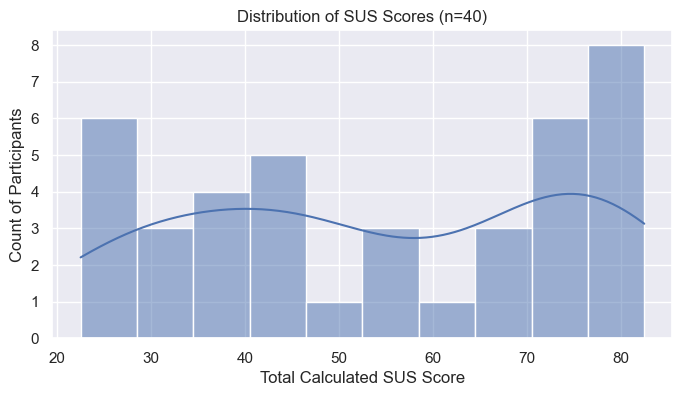

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Basic distribution check
plt.figure(figsize=(8, 4))
sns.histplot(SUS_scores["Total_Calculated_SUS"], kde=True, bins=10)

# Clean, simple labeling
plt.title("Distribution of SUS Scores (n=40)")
plt.xlabel("Total Calculated SUS Score")
plt.ylabel("Count of Participants")

plt.show()


##### Key Insights from SUS Distribution

• **Two Distinct Peaks (Bimodal Split):** The graph shows that the banking app experience completely polarized users. They tend to split into two separate groups:

- The Frustrated Peak (Far Left): 6 participants scored the app extremely low, between 22 and 28. These users found the app highly frustrating or unusable.

- The Successful Peak (Far Right): 8 participants scored the app very high, between 76 and 82. These users found the app seamless and easy.

• **The Empty Middle (48 to 64):** Very few users gave a middle-of-the-road score. They either loved the app or hated it.

NOTE: Reporting a single "average" score of 68.5 is misleading because almost no one actually had an average experience. We must use demographic filters in Power BI to see exactly who makes up that frustrated group on the left.

### 4. Data Export

In [26]:
participants.columns = participants.columns.str.lower()
participants.head()

,participant_id,age_group,account_type,tech_literacy,mobile_os
0,P001,35-54,Retail,Low,Android
1,P002,55+,Retail,Low,Android
2,P003,35-54,Retail,Medium,iOS
3,P004,35-54,Business,High,iOS
4,P005,18-34,Retail,High,iOS


In [27]:
task_performance.columns = task_performance.columns.str.lower()
task_performance.head()

,record_id,participant_id,task_name,is_successful,time_on_task_sec,error_count
0,R001,P001,1. Biometric Login,1,74,0
1,R002,P001,2. Send Money,1,175,1
2,R003,P001,3. Bill Pay,1,199,0
3,R004,P002,1. Biometric Login,1,67,0
4,R005,P002,2. Send Money,0,220,2


In [28]:
SUS_scores.columns = SUS_scores.columns.str.lower()
SUS_scores.head()

,participant_id,sus_q1,sus_q2,sus_q3,sus_q4,sus_q5,sus_q6,sus_q7,sus_q8,sus_q9,sus_q10,total_calculated_sus
0,P001,2,2,1,2,1,4,3,4,3,2,40.0
1,P002,1,3,2,3,1,3,1,4,2,3,27.5
2,P003,2,2,2,3,2,3,2,2,2,2,45.0
3,P004,3,1,5,2,3,2,3,1,4,2,75.0
4,P005,3,1,3,1,2,3,5,1,4,2,72.5


In [29]:
qualitative_insights.columns = qualitative_insights.columns.str.lower()
qualitative_insights.head()

,insight_id,participant_id,task_name,severity,issue_description,user_quote
0,I001,P002,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,Why would a banking application intentionally ...
1,I002,P002,3. Bill Pay,Critical,Barcode scanner component failed under ambient...,"The flash doesn't turn on, so in the evening n..."
2,I003,P003,2. Send Money,Critical,IBAN formatting strictly prohibited pasted str...,"I copied this right from my email, why does th..."
3,I004,P003,3. Bill Pay,Minor,Future-dated schedule selector wheel used ambi...,Confusing calendar icons make it impossible to...
4,I005,P004,2. Send Money,Minor,Beneficiary name character limit cut off long ...,"The name of my supplier won't fit here, it kee..."


In [30]:
# Export the complete 4-table relational model to CSV
participants.to_csv("participants.csv", index=False)
task_performance.to_csv("task_performance.csv", index=False)
SUS_scores.to_csv("SUS_scores.csv", index=False)
qualitative_insights.to_csv("qualitative_insights.csv", index=False)

print("Success: All 4 clean data structures exported as CSV files!")

Success: All 4 clean data structures exported as CSV files!
